## Run script

In [ ]:
# !bash ../UniPert/run_scripts/run_embedder_gs.sh

Starting grid search...
Experiment with tgt=ESM2, cp=ECFP4 started on GPU 1. Logs saved to /data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/saved_models/unipert_embedder_gs/ESM2_ECFP4.log
Experiment with tgt=ESM2, cp=UniMol started on GPU 2. Logs saved to /data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/saved_models/unipert_embedder_gs/ESM2_UniMol.log
Experiment with tgt=ESM2, cp=KPGT started on GPU 3. Logs saved to /data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/saved_models/unipert_embedder_gs/ESM2_KPGT.log
Experiment with tgt=OntoProtein, cp=ECFP4 started on GPU 4. Logs saved to /data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/saved_models/unipert_embedder_gs/OntoProtein_ECFP4.log
Experiment with tgt=OntoProtein, cp=UniMol started on GPU 5. Logs saved to /data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/saved_models/unipert_embedder_gs/OntoProtein_UniMol.log
Experiment with tgt=OntoProtein, cp=KPGT started on GPU 0. Logs saved to /data/liyiming/Project/UniPe

In [ ]:
# !bash ../UniPert/run_scripts/run_gnn_ln_od_gs.sh

Starting grid search...
Experiment with gnn_type=GCN, layer_num=1, out_dim=64, started on GPU 4. Logs saved to /data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/saved_models/unipert_gnn_gs/GCN_1_64.log
Experiment with gnn_type=GCN, layer_num=1, out_dim=128, started on GPU 5. Logs saved to /data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/saved_models/unipert_gnn_gs/GCN_1_128.log
Experiment with gnn_type=GCN, layer_num=1, out_dim=256, started on GPU 0. Logs saved to /data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/saved_models/unipert_gnn_gs/GCN_1_256.log
Experiment with gnn_type=GCN, layer_num=2, out_dim=64, started on GPU 1. Logs saved to /data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/saved_models/unipert_gnn_gs/GCN_2_64.log
Experiment with gnn_type=GCN, layer_num=2, out_dim=128, started on GPU 2. Logs saved to /data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/saved_models/unipert_gnn_gs/GCN_2_128.log
Experiment with gnn_type=GCN, layer_num=2, out_dim=256, star

## Download results

python -m tensorboard.main --logdir ./ --port 6007 --host 127.0.0.1

In [ ]:
# !python -m tensorboard.main --logdir ../UniPert/saved_models/unipert_embedder_gs --port 6007 --host 127.0.0.1
# !python -m tensorboard.main --logdir ../UniPert/saved_models/unipert_gnn_gs --port 6007 --host 127.0.0.1

## Plot func

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import fontManager, FontProperties
import seaborn as sns

# === 注册 Helvetica 字体 ===
font_path = "../Helvetica.ttf"
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()

# === 设置绘图全局参数 ===
sns.set_theme(
    style="ticks",
    context="paper",
    font_scale=1.1,
    rc={
        "axes.linewidth": 0.5,
        "axes.edgecolor": "black",
        "axes.labelsize": 9,
        "axes.titlesize": 9,
        # "axes.titleweight": "bold",
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "legend.frameon": False,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.size": 2,
        "ytick.major.size": 2,
        "figure.dpi": 150,
        "savefig.dpi": 600,
        "axes.facecolor": (0, 0, 0, 0),
    }
)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name]   
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["legend.facecolor"] = "white"
# plt.rcParams["legend.edgecolor"] = "none"

print(f"✅ Loaded custom font: {font_name}")

✅ Loaded custom font: Helvetica


## Results: compound / target embedder

In [ ]:
import pandas as pd

file_path = '../UniPert/results/hparams_table_embedder_gs.csv'
df = pd.read_csv(file_path)
len(df)

9

In [ ]:
pd.crosstab(df['compound_embedder'], df['target_embedder'])

target_embedder,ESM2,OntoProtein,PseAAC
compound_embedder,,,
ECFP4,1,1,1
KPGT,1,1,1
UniMol,1,1,1


In [ ]:
df.groupby(['compound_embedder'])[['hparam/tgt_loss', 'hparam/ctc_loss']].mean()

,hparam/tgt_loss,hparam/ctc_loss
compound_embedder,,
ECFP4,0.031962,4.322374
KPGT,0.031578,4.444694
UniMol,0.033147,5.100237


In [ ]:
df.groupby(['target_embedder'])[['hparam/tgt_loss', 'hparam/ctc_loss']].mean()

,hparam/tgt_loss,hparam/ctc_loss
target_embedder,,
ESM2,0.013284,4.591003
OntoProtein,0.016163,4.593338
PseAAC,0.067240,4.682964


### plot

In [ ]:
df['target_embedder'] = df['target_embedder'].replace({'ESM2': 'ESM'})

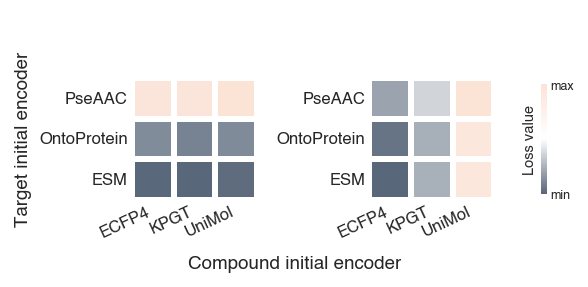

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle

cmap = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["#59677A", "w", "#FBE3D6"]) 

tgt_loss_pivot = df.pivot_table(
    index='target_embedder',
    columns='compound_embedder',
    values='hparam/tgt_loss',
    aggfunc='mean'
)

ctc_loss_pivot = df.pivot_table(
    index='target_embedder',
    columns='compound_embedder',
    values='hparam/ctc_loss',
    aggfunc='mean'
)

row_order = ['PseAAC', 'OntoProtein', 'ESM']      # y ：target_embedder
col_order = ['ECFP4', 'KPGT', 'UniMol']            # x ：compound_embedder

tgt_loss_pivot = tgt_loss_pivot.reindex(index=row_order, columns=col_order)
ctc_loss_pivot = ctc_loss_pivot.reindex(index=row_order, columns=col_order)


fig, axes = plt.subplots(1, 2, figsize=(3.5, 1.35))
norm = mcolors.PowerNorm(
    gamma=0.75,
    vmin=tgt_loss_pivot.min().min(),
    vmax=tgt_loss_pivot.max().max()
)
sns.heatmap(
    tgt_loss_pivot,
    ax=axes[0],
    fmt=".2f",
    cmap=cmap,
    norm=norm,
    cbar=False,
    linewidths=2,      
    linecolor='white'   
)
axes[0].set_title('\n', pad=15)
axes[0].set_xlabel('Compound initial encoder')  
axes[0].xaxis.set_label_coords(x=1.3, y=-0.45)
axes[0].set_ylabel('Target initial encoder')    
axes[0].yaxis.set_label_coords(x=-0.8, y=0.5)


norm = mcolors.PowerNorm(
    gamma=0.75,
    vmin=ctc_loss_pivot.min().min(),
    vmax=ctc_loss_pivot.max().max()
)
sns.heatmap(
    ctc_loss_pivot,
    ax=axes[1],
    fmt=".2f",
    cmap=cmap,
    norm=norm,
    cbar=False,
    linewidths=2,      
    linecolor='white'    
)

axes[1].set_title('\n', pad=15)
axes[1].set_xlabel('')
axes[1].set_ylabel('') 
for ax in axes:
    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=25,      
        ha='right',
        fontsize=8      
    )
    ax.set_yticklabels(
        ax.get_yticklabels(),
        rotation=0,
        fontsize=8
    )

    ax.tick_params(
        axis='both',
        which='both',
        direction='out', 
        width=0.,        
        length=2,         
        pad=0          
    )

cbar = axes[0].collections[0].colorbar  # 取第一个 heatmap 的 colorbar
vmin = min(tgt_loss_pivot.min().min(), ctc_loss_pivot.min().min())
vmax = max(tgt_loss_pivot.max().max(), ctc_loss_pivot.max().max())
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])  

bbox = axes[1].get_position()
cax = fig.add_axes([
    bbox.x1 - 0.02,        
    bbox.y0 + 0.22,        
    0.01,                  
    bbox.height * 0.7      
])

cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("Loss value", fontsize=7, labelpad=-24)
cbar.set_ticks([vmin, vmax])
cbar.ax.set_yticklabels(['min', 'max'], fontsize=6)
cbar.ax.tick_params(width=0.4, length=0, direction='out', pad=1.5)
cbar.outline.set_linewidth(0.0)

plt.subplots_adjust(
    left=0.1,  
    right=0.79, 
    bottom=0.3,
    top=0.9,
    wspace=0.9,  
    hspace=0.2  
)

plt.show()

## Results: graph layer_num / out_dim

In [ ]:
import pandas as pd
file_path = '../UniPert/results/hparams_table_gnn_ln_od_gs.csv'
df = pd.read_csv(file_path)
len(df)

9

In [ ]:
pd.crosstab(df['layer_num'], df['out_dim'])


out_dim,64.0,128.0,256.0
layer_num,,,
1.0,1,1,1
2.0,1,1,1
3.0,1,1,1


In [ ]:
df.groupby(['layer_num', 'out_dim'])[['hparam/tgt_loss', 'hparam/ctc_loss']].mean()

hparam/tgt_loss  hparam/ctc_loss
layer_num out_dim                                  
1.0       64.0            0.019362         4.574713
          128.0           0.023268         4.381621
          256.0           0.025166         4.238808
2.0       64.0            0.014688         4.599417
          128.0           0.016802         4.390243
          256.0           0.013051         4.269117
3.0       64.0            0.013413         4.583854
          128.0           0.013872         4.406377
          256.0           0.010595         4.286376

In [ ]:
df.groupby('layer_num')[['hparam/tgt_loss', 'hparam/ctc_loss']].mean()

,hparam/tgt_loss,hparam/ctc_loss
layer_num,,
1.0,0.022599,4.398381
2.0,0.014847,4.419592
3.0,0.012627,4.425535


In [ ]:
df.groupby('out_dim')[['hparam/tgt_loss', 'hparam/ctc_loss']].mean()

,hparam/tgt_loss,hparam/ctc_loss
out_dim,,
64.0,0.015821,4.585994
128.0,0.017981,4.392747
256.0,0.016271,4.264767


### plot

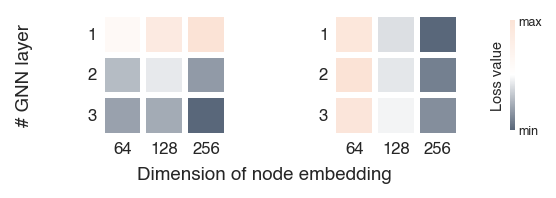

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle

cmap = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["#59677A", "w", "#FBE3D6"])  # Adjust colors as needed

tgt_loss_pivot = df.pivot_table(
    index='layer_num',
    columns='out_dim',
    values='hparam/tgt_loss',
    aggfunc='mean'
)
ctc_loss_pivot = df.pivot_table(
    index='layer_num',
    columns='out_dim',
    values='hparam/ctc_loss',
    aggfunc='mean'
)
row_order = [1, 2, 3]      
col_order = [64, 128, 256]   

tgt_loss_pivot = tgt_loss_pivot.reindex(index=row_order, columns=col_order)
ctc_loss_pivot = ctc_loss_pivot.reindex(index=row_order, columns=col_order)

fig, axes = plt.subplots(1, 2, figsize=(3.4, 1.35))
sns.heatmap(
    tgt_loss_pivot,
    ax=axes[0],
    fmt=".2f",
    cmap=cmap,
    cbar=False,
    linewidths=2,      
    linecolor='white'    
)

axes[0].set_title('', pad=15)
axes[0].set_xlabel('Dimension of node embedding')   
axes[0].xaxis.set_label_coords(x=1.3, y=-0.25)
axes[0].set_ylabel('# GNN layer')    
axes[0].yaxis.set_label_coords(x=-0.55, y=0.5)
sns.heatmap(
    ctc_loss_pivot,
    ax=axes[1],
    fmt=".2f",
    cmap=cmap,
    cbar=False,
    linewidths=2,     
    linecolor='white'    
)
axes[1].set_title('', pad=15)
axes[1].set_xlabel('')
axes[1].set_ylabel('') 


for ax in axes:
    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=0,      
        ha='center',
        fontsize=8        
    )
    ax.set_yticklabels(
        ax.get_yticklabels(),
        rotation=0,
        fontsize=8
    )

    ax.tick_params(
        axis='both',
        which='both',
        direction='out',  
        width=0.,        
        length=2,         
        pad=0.5           
    )


cbar = axes[0].collections[0].colorbar  
vmin = min(tgt_loss_pivot.min().min(), ctc_loss_pivot.min().min())
vmax = max(tgt_loss_pivot.max().max(), ctc_loss_pivot.max().max())
norm = Normalize(vmin=vmin, vmax=vmax)
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])  

bbox = axes[1].get_position() 
cax = fig.add_axes([
    bbox.x1,        
    bbox.y0 + 0.22,       
    0.01,                  
    bbox.height * 0.7      
])

cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("Loss value", fontsize=7, labelpad=-24)
cbar.set_ticks([vmin, vmax])
cbar.ax.set_yticklabels(['min', 'max'], fontsize=6)
cbar.ax.tick_params(width=0.4, length=0, direction='out', pad=1.5)
cbar.outline.set_linewidth(0.0)

plt.subplots_adjust(
    left=0.1,  
    right=0.8,  
    bottom=0.3,
    top=0.9,
    wspace=0.85,  
    hspace=0.2   
)

plt.show()